# Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp

# Global parameters
r_list = [-1.0, 0.0, 1.0]
x0_list = [-1.5, -0.5, 0.5, 1.5]
r_os = np.linspace(-2, 2, 801)
eps = 0.02            # hitrost spreminjanja r(t)
x_meja = 3.0          # meja za ustavitev pobega v neskoncnost

# Funkcije

In [2]:
# Simbolno: normalne forme, ravnotezja in lastne vrednosti lambda = df/dx
x, r = sp.symbols("x r", real=True)
forme = {
    "Sedelno-vozelna": r - x**2,
    "Transkritična": r * x - x**2,
    "Nadkritična vilična": r * x - x**3,
    "Podkritična vilična": r * x + x**3,
}
veje = {ime: sp.solve(f, x) for ime, f in forme.items()}
lam = {ime: sp.diff(f, x) for ime, f in forme.items()}

In [3]:
def rhs(t, y, f_np, r):
    return [f_np(y[0], r)]

def pobeg(t, y, *args):
    return x_meja - abs(y[0])
pobeg.terminal = True

def casovni_potek(f_np, r, x0, t_max=10.0):
    return solve_ivp(rhs, (0, t_max), [x0], args=(f_np, r), events=pobeg,
                     max_step=0.01, rtol=1e-9, atol=1e-12)

def fazna_premica(ax, f_sym, r_val, x_os=np.linspace(-2, 2, 400)):
    f_np = sp.lambdify(x, f_sym.subs(r, r_val), "numpy")
    ax.plot(x_os, f_np(x_os) * np.ones_like(x_os))
    ax.axhline(0, color="black", linewidth=0.8)
    # puscice toka na osi x
    for xa in np.linspace(-1.8, 1.8, 10):
        s = np.sign(f_np(xa))
        if s != 0:
            ax.annotate("", xy=(xa + 0.12 * s, 0), xytext=(xa - 0.12 * s, 0),
                        arrowprops=dict(arrowstyle="->", color="C1", lw=1.5))
    # ravnotezja: polni = stabilna, prazni = nestabilna
    l_np = sp.lambdify(x, sp.diff(f_sym, x).subs(r, r_val), "numpy")
    for xs in set(sp.solve(f_sym.subs(r, r_val), x)):
        if xs.is_real:
            xs = float(xs)
            stab = l_np(xs) < 0
            ax.plot(xs, 0, "o", markersize=9, color="black",
                    markerfacecolor="black" if stab else "white", zorder=5)
    ax.set_xlabel("$x$", fontsize=14)
    ax.set_ylabel(r"$\dot{x}$", fontsize=14)
    ax.set_title(f"$r = {r_val}$")
    ax.grid(alpha=0.3)

def bif_diagram(ax, ime, r_os=r_os):
    # polna crta = stabilna veja, crtkana = nestabilna
    l_np = sp.lambdify((x, r), lam[ime], "numpy")
    for veja in veje[ime]:
        v_np = sp.lambdify(r, veja, "numpy")
        with np.errstate(invalid="ignore"):
            x_v = np.real_if_close(v_np(r_os.astype(complex)) * np.ones_like(r_os))
        x_v = np.where(np.abs(np.imag(x_v)) < 1e-12, np.real(x_v), np.nan)
        l_v = l_np(x_v, r_os)
        ax.plot(r_os, np.where(l_v < 0, x_v, np.nan), "-", color="C0", linewidth=2)
        ax.plot(r_os, np.where(l_v > 0, x_v, np.nan), "--", color="C3", linewidth=2)
    ax.plot(0, 0, "o", color="black", markersize=6)
    ax.set_xlabel("$r$", fontsize=14)
    ax.set_ylabel("$x^*$", fontsize=14)
    ax.set_title(f"{ime}: $\\dot{{x}} = {sp.latex(forme[ime])}$")
    ax.grid(alpha=0.3)

# Testno območje

In [4]:
# Pripravljalna naloga: transkriticna bifurkacija
ime = "Transkritična"
for veja in veje[ime]:
    l = lam[ime].subs(x, veja)
    oznaka = {r_v: ("stabilno" if l.subs(r, r_v) < 0 else "nestabilno") for r_v in (-1, 1)}
    print(f"x* = {veja}:  lambda = {l},  r = -1 -> {oznaka[-1]},  r = +1 -> {oznaka[1]}")

x* = 0:  lambda = r,  r = -1 -> stabilno,  r = +1 -> nestabilno
x* = r:  lambda = -r,  r = -1 -> nestabilno,  r = +1 -> stabilno


In [5]:
# Pregled vseh normalnih form
for ime in forme:
    print(f"{ime:20s} f = {str(forme[ime]):12s}  x* = {veje[ime]},  lambda = {lam[ime]}")

Sedelno-vozelna      f = r - x**2      x* = [-sqrt(r), sqrt(r)],  lambda = -2*x
Transkritična        f = r*x - x**2    x* = [0, r],  lambda = r - 2*x
Nadkritična vilična  f = r*x - x**3    x* = [0, -sqrt(r), sqrt(r)],  lambda = r - 3*x**2
Podkritična vilična  f = r*x + x**3    x* = [0, -sqrt(-r), sqrt(-r)],  lambda = r + 3*x**2


# Naloga 1

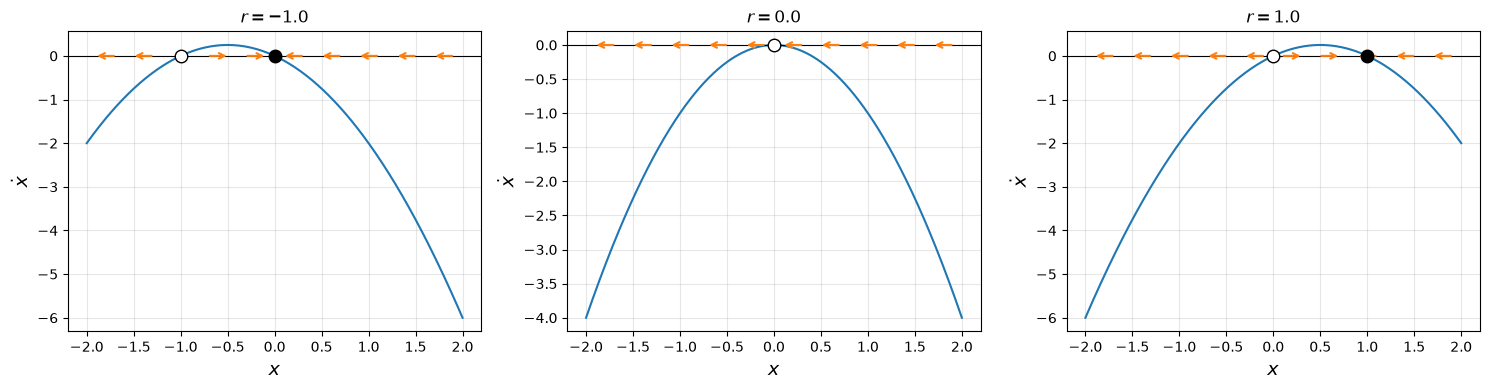

In [6]:
fig = plt.figure(figsize=(15, 4))
for i, r_val in enumerate(r_list):
    ax = fig.add_subplot(1, 3, i + 1)
    fazna_premica(ax, forme["Transkritična"], r_val)
plt.tight_layout()
plt.show()

r = -1, x0 = -1.5: pobeg proti -inf, |x| = 3.0 pri t = 0.69
r = +1, x0 = -1.5: pobeg proti -inf, |x| = 3.0 pri t = 0.22
r = +1, x0 = -0.5: pobeg proti -inf, |x| = 3.0 pri t = 0.81


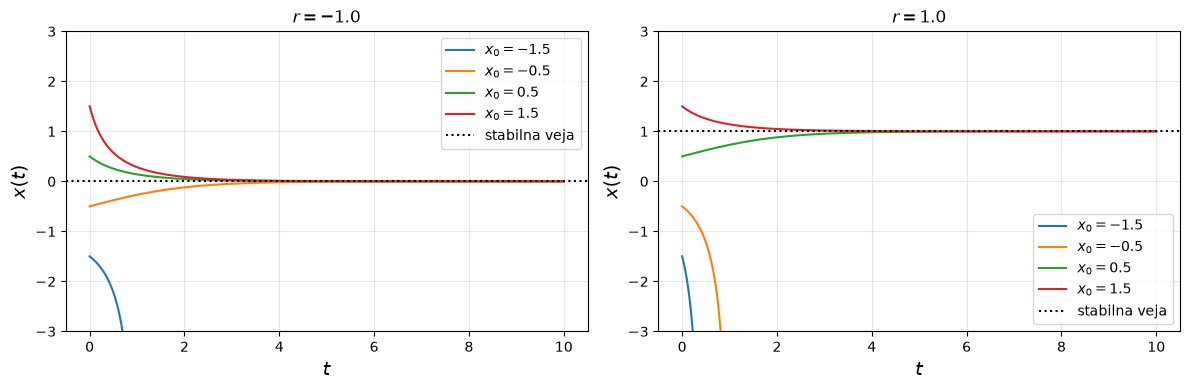

In [7]:
f_tk = sp.lambdify((x, r), forme["Transkritična"], "numpy")

fig = plt.figure(figsize=(12, 4))
for i, r_val in enumerate([-1.0, 1.0]):
    ax = fig.add_subplot(1, 2, i + 1)
    for x0 in x0_list:
        sol = casovni_potek(f_tk, r_val, x0)
        ax.plot(sol.t, sol.y[0], label=f"$x_0 = {x0}$")
        if sol.status == 1:
            print(f"r = {r_val:+.0f}, x0 = {x0:+.1f}: pobeg proti -inf, |x| = {x_meja} pri t = {sol.t[-1]:.2f}")
    ax.axhline(max(r_val, 0), color="black", linestyle=":", label="stabilna veja")
    ax.set_ylim(-x_meja, x_meja)
    ax.set_xlabel("$t$", fontsize=14)
    ax.set_ylabel("$x(t)$", fontsize=14)
    ax.set_title(f"$r = {r_val}$")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Naloga 2

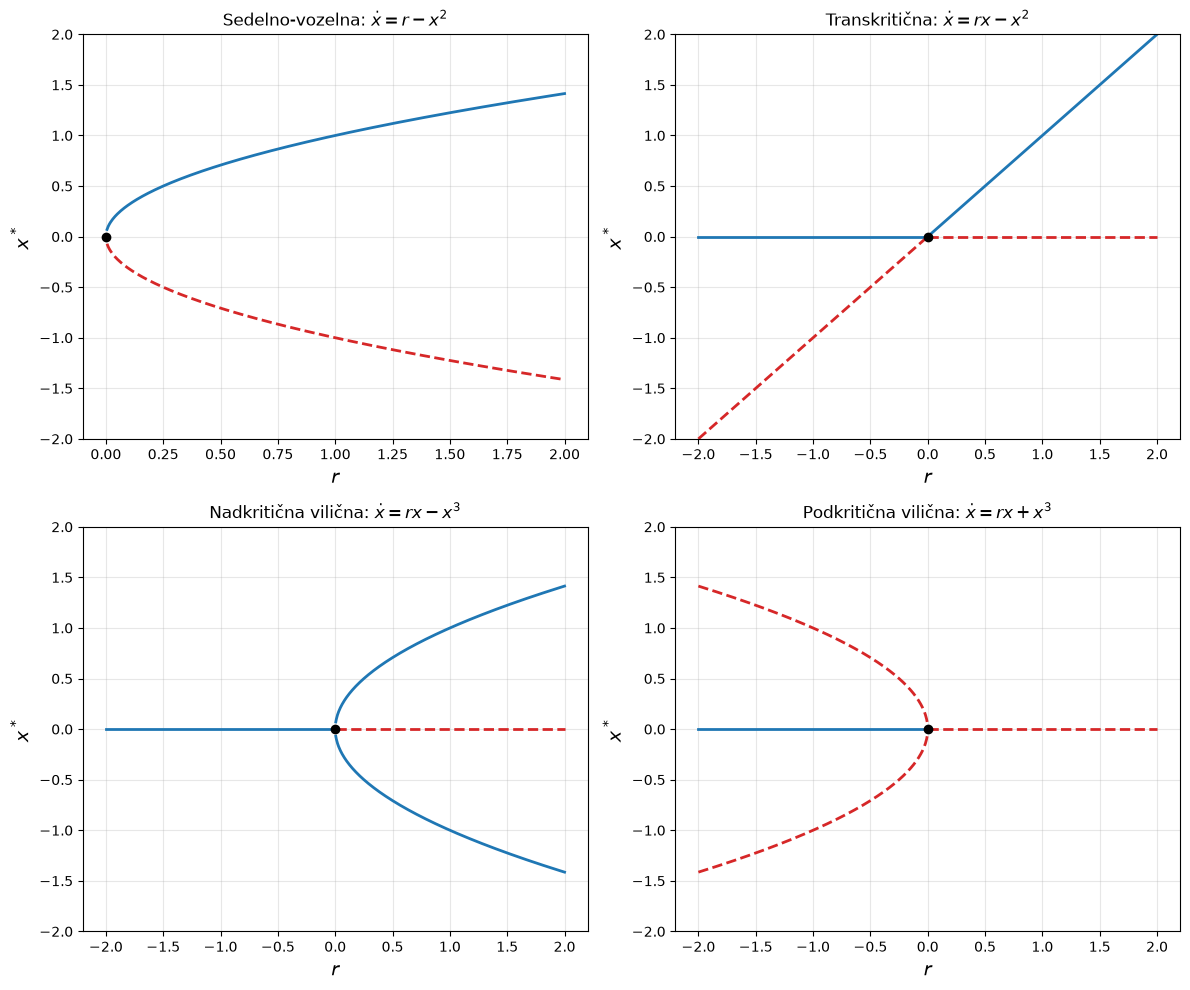

In [8]:
fig = plt.figure(figsize=(12, 10))
for i, ime in enumerate(forme):
    ax = fig.add_subplot(2, 2, i + 1)
    bif_diagram(ax, ime)
    ax.set_ylim(-2, 2)
plt.tight_layout()
plt.show()

# Naloga 3

pobeg iz veje x = 0 (x > 0.1) pri r = 1.045  (r_c = 0)


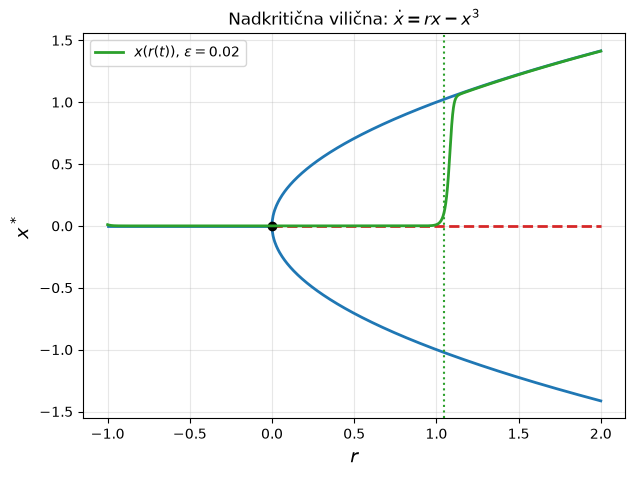

In [9]:
# Pocasno spreminjanje r(t) = -1 + eps t skozi nadkriticno vilicno bifurkacijo
f_pf = sp.lambdify((x, r), forme["Nadkritična vilična"], "numpy")

def rhs_r(t, y):
    return [f_pf(y[0], -1.0 + eps * t)]

t_end = 3.0 / eps
sol = solve_ivp(rhs_r, (0, t_end), [0.01], max_step=0.05, rtol=1e-10, atol=1e-14)
r_t = -1.0 + eps * sol.t
r_pobeg = r_t[np.argmax(sol.y[0] > 0.1)]
print(f"pobeg iz veje x = 0 (x > 0.1) pri r = {r_pobeg:.3f}  (r_c = 0)")

fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(111)
bif_diagram(ax, "Nadkritična vilična", np.linspace(-1, 2, 600))
ax.plot(r_t, sol.y[0], color="C2", linewidth=2, label=r"$x(r(t))$, $\epsilon = 0.02$")
ax.axvline(r_pobeg, color="C2", linestyle=":")
ax.legend()
plt.show()

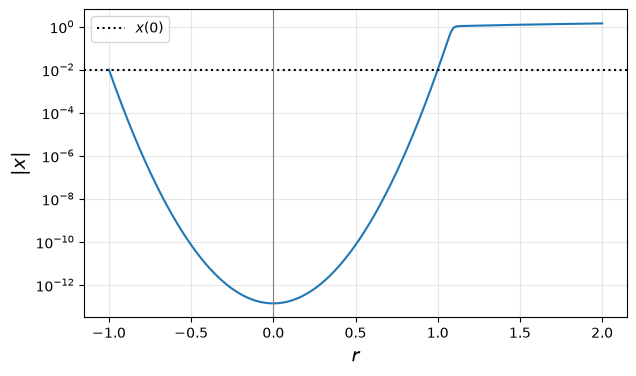

In [10]:
# |x| v log skali: x pada dokler r < 0 in naraste nazaj na x(0) pri r ~ +1
fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(111)
ax.semilogy(r_t, np.abs(sol.y[0]))
ax.axhline(0.01, color="black", linestyle=":", label="$x(0)$")
ax.axvline(0, color="gray", linewidth=0.8)
ax.set_xlabel("$r$", fontsize=14)
ax.set_ylabel("$|x|$", fontsize=14)
ax.legend()
ax.grid(alpha=0.3, which="both")
plt.show()

# Razmislek 1

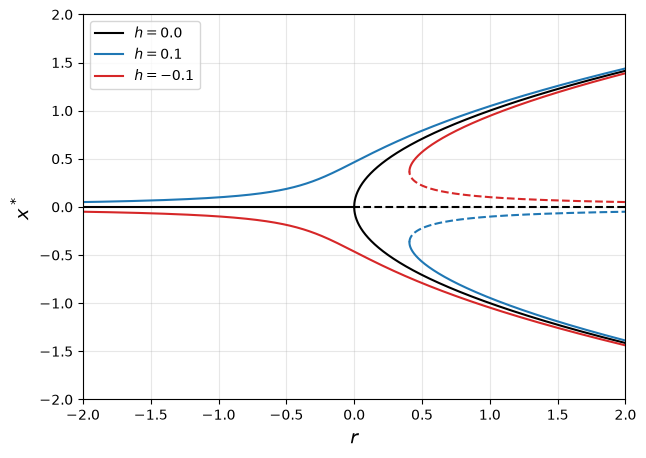

In [11]:
# Nepopolna vilicna bifurkacija x' = h + r x - x^3: veje parametriziramo z x
x_par = np.linspace(-2, 2, 2000)

fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(111)
for h, c in [(0.0, "black"), (0.1, "C0"), (-0.1, "C3")]:
    with np.errstate(divide="ignore", invalid="ignore"):
        r_par = (x_par**3 - h) / x_par
    l_par = r_par - 3 * x_par**2
    ax.plot(np.where(l_par < 0, r_par, np.nan), x_par, "-", color=c, label=f"$h = {h}$")
    ax.plot(np.where(l_par > 0, r_par, np.nan), x_par, "--", color=c)
r_neg = np.linspace(-2, 0, 50)
ax.plot(r_neg, 0 * r_neg, "-", color="black")
ax.plot(-r_neg, 0 * r_neg, "--", color="black")
ax.set_xlim(-2, 2)
ax.set_ylim(-2, 2)
ax.set_xlabel("$r$", fontsize=14)
ax.set_ylabel("$x^*$", fontsize=14)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

# Razmislek 2

r = 0.05: |x| = 3.0 dosezen pri t = 17.9
r = 0.1: |x| = 3.0 dosezen pri t = 11.9


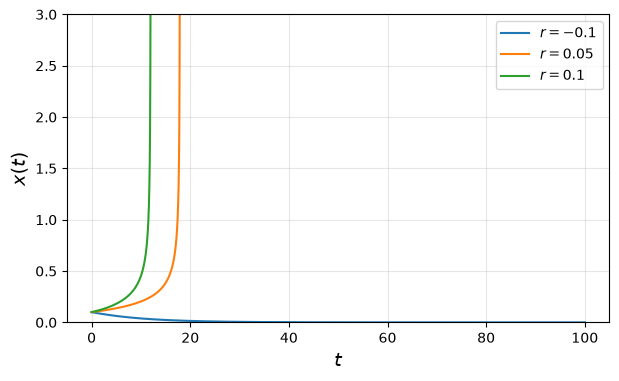

In [12]:
# Podkriticna vilicna: pri r > 0 majhna motnja pobegne v koncnem casu
f_sub = sp.lambdify((x, r), forme["Podkritična vilična"], "numpy")

fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(111)
for r_val in [-0.1, 0.05, 0.1]:
    sol = casovni_potek(f_sub, r_val, 0.1, t_max=100)
    ax.plot(sol.t, sol.y[0], label=f"$r = {r_val}$")
    if sol.status == 1:
        print(f"r = {r_val}: |x| = {x_meja} dosezen pri t = {sol.t[-1]:.1f}")
ax.set_ylim(0, x_meja)
ax.set_xlabel("$t$", fontsize=14)
ax.set_ylabel("$x(t)$", fontsize=14)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

# Razmislek 3

r = -1.00: tau_num =    1.00,  1/|r| =    1.00
r = -0.50: tau_num =    2.00,  1/|r| =    2.00
r = -0.20: tau_num =    5.00,  1/|r| =    5.00
r = -0.10: tau_num =   10.00,  1/|r| =   10.00
r = -0.05: tau_num =   19.98,  1/|r| =   20.00
r = -0.02: tau_num =   49.89,  1/|r| =   50.00


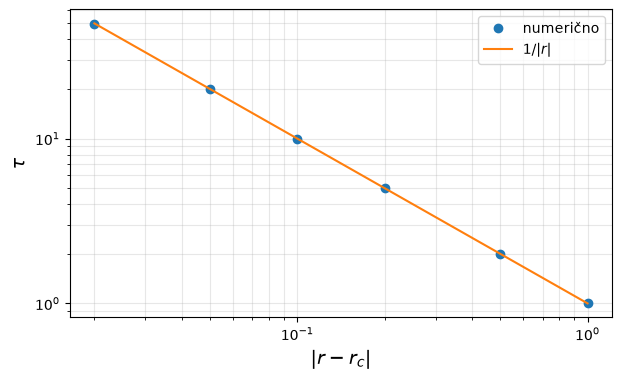

In [13]:
# Kriticna upocasnitev: relaksacijski cas tau = 1/|lambda| = 1/|r| (nadkriticna vilicna, r < 0)
r_vals = np.array([-1.0, -0.5, -0.2, -0.1, -0.05, -0.02])
tau_num = []
for r_val in r_vals:
    sol = solve_ivp(rhs, (0, 500), [0.01], args=(f_pf, r_val), dense_output=True, rtol=1e-10, atol=1e-14)
    t_f = np.linspace(0, 500, 200001)
    tau_num.append(t_f[np.argmax(sol.sol(t_f)[0] < 0.01 / np.e)])
tau_num = np.array(tau_num)
for r_val, tn in zip(r_vals, tau_num):
    print(f"r = {r_val:+.2f}: tau_num = {tn:7.2f},  1/|r| = {1 / abs(r_val):7.2f}")

fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(111)
ax.loglog(np.abs(r_vals), tau_num, "o", label="numerično")
ax.loglog(np.abs(r_vals), 1 / np.abs(r_vals), "-", label=r"$1/|r|$")
ax.set_xlabel(r"$|r - r_c|$", fontsize=14)
ax.set_ylabel(r"$\tau$", fontsize=14)
ax.legend()
ax.grid(alpha=0.3, which="both")
plt.show()